# <a id='toc1_'></a>[Baseline](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [Baseline](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
    - [Separação treino e teste - validação cruzada](#toc1_2_1_)    
    - [Aplicando o baseline](#toc1_2_2_)    
  - [Conclusão](#toc1_3_)    
  - [Referências](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Nesse notebook, iremos implementar o modelo baseline ao nosso dataset. Esse modelo é o mais simples possível, e servirá para termos uma base quando formos avaliar o desempenho de modelos mais complexos. 

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

Vamos iniciar coletando os dados que iremos utilizar.

In [49]:
import pandas as pd

df_earthquakes = pd.read_csv("../00 - Coleta e Tratamento de Dados/Data/earthquake_dataset_treated.csv")
df_earthquakes

,event_id,latitude,longitude,epicenter_distance,geodesic_distance,azimuth_degree,magnitude,magnitude_type,depth,origin_time,...,noise_region,min_amplitude,max_amplitude,amplitude_std,amplitude_region,std_factor,amplitude_factor,first_arrival,last_arrival,amplitude_factor_log10
0,Cuba Region2020-01-28T19:10:22.861893Z,19.339197,-78.801216,52.318245,5.800753e+06,142.025918,7.547371,Mwp,0.000000,2020-01-28T19:10:22.861893Z,...,"{'x0': np.float64(1580237376.0), 'x1': np.floa...",0.0,27236.564300,1377.535261,"{'x0': 1580239116.1732109, 'x1': 1580241924.49...",0.127866,0.611030,1.580239e+09,1.580242e+09,-0.213937
1,Kuril Islands2020-02-13T10:33:38.812968Z,45.465420,149.276504,153.733322,1.709241e+07,35.499121,7.017215,mB,121.251366,2020-02-13T10:33:38.812968Z,...,"{'x0': np.float64(1581589268.0), 'x1': np.floa...",0.0,50948.537640,11216.897473,"{'x0': 1581591008.3566542, 'x1': 1581595453.0,...",0.986074,1.066733,1.581591e+09,1.581595e+09,0.028056
2,East of Kuril Islands2020-03-25T02:49:11.159690Z,49.006786,158.678940,146.856493,1.632796e+07,46.754932,7.604934,mB,10.000000,2020-03-25T02:49:11.159690Z,...,"{'x0': np.float64(1585103784.0), 'x1': np.floa...",0.0,0.006025,0.001362,"{'x0': 1585105524.2211037, 'x1': 1585109766.0,...",1.014633,1.031189,1.585106e+09,1.585110e+09,0.013338
3,South of Kermadec Islands2020-06-18T12:49:53.2...,-33.407040,-178.260696,107.069040,1.192499e+07,133.584818,7.312320,mB,10.000000,2020-06-18T12:49:53.203849Z,...,"{'x0': np.float64(1592483650.0), 'x1': np.floa...",0.0,24523.256959,2185.540188,"{'x0': 1592485389.6519437, 'x1': 1592488009.0,...",0.483855,0.948059,1.592485e+09,1.592488e+09,-0.023165
4,"Oaxaca, Mexico2020-06-23T15:29:05.856787Z",16.016554,-95.881226,61.554104,6.835611e+06,127.712764,7.411209,mB,38.273556,2020-06-23T15:29:05.856787Z,...,"{'x0': np.float64(1592924959.0), 'x1': np.floa...",0.0,1744.718093,337.400559,"{'x0': 1592926699.0376651, 'x1': 1592929425.27...",1.312458,1.170427,1.592927e+09,1.592929e+09,0.068344
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
439,Southern Mid-Atlantic Ridge2026-10-13T08:38:28...,-28.499863,-12.648232,31.421167,3.499362e+06,272.389218,5.282686,mb,0.000000,2026-10-13T08:38:28.868149Z,...,"{'x0': np.float64(1791879292.0), 'x1': np.floa...",0.0,59093.897848,13071.317397,"{'x0': 1791881031.6703076, 'x1': 1791884030.24...",0.999571,1.001455,1.791881e+09,1.791884e+09,0.000632
440,Off Coast of Ecuador2026-10-16T19:34:13.063601Z,1.210575,-85.026466,44.085385,4.899086e+06,125.222618,5.227027,mb,10.000000,2026-10-16T19:34:13.063601Z,...,"{'x0': np.float64(1792177941.0), 'x1': np.floa...",0.0,119.632126,25.131914,"{'x0': 1792179681.1553068, 'x1': 1792182560.59...",1.035958,1.041796,1.792180e+09,1.792183e+09,0.017783
441,Solomon Islands2026-10-24T02:31:13.659376Z,-8.499777,157.692154,140.415230,1.562654e+07,142.953590,7.006438,Mwp,10.000000,2026-10-24T02:31:13.659376Z,...,"{'x0': np.float64(1792808278.0), 'x1': np.floa...",0.0,132.865801,28.991444,"{'x0': 1792810018.128538, 'x1': 1792813530.0, ...",1.147345,1.109488,1.792810e+09,1.792813e+09,0.045123
442,Bouvet Island Region2026-10-24T15:24:26.259182Z,-53.687351,6.795708,50.625117,5.634061e+06,285.550006,5.949712,mb,43.653282,2026-10-24T15:24:26.259182Z,...,"{'x0': np.float64(1792854201.0), 'x1': np.floa...",0.0,119.316019,25.279636,"{'x0': 1792855940.7418182, 'x1': 1792858757.95...",0.948364,0.997025,1.792856e+09,1.792859e+09,-0.001294


Nem todas as informações da nossa tabela serão utilizadas pelos nossos modelos. Vamos iniciar definindo os atributos e target.

In [50]:
ATTRIBUTES = [
    "epicenter_distance",
    "geodesic_distance",
    "azimuth_degree",
    "magnitude",
    "magnitude_type",
    "depth",
    "first_arrival_time_delta",
    "arrival_time_delta",
    "earth_water_ratio",
    "origin_plate"
]

TARGET = [
    "amplitude_factor"
]

X = df_earthquakes.reindex(ATTRIBUTES, axis=1)
y = df_earthquakes.reindex(TARGET, axis=1)

Temos dois atributos categóricos em nosso dataset: `magnitude_type` e `origin_plate`. Vamos utilizar o codificador one-hot para transformá-los em colunas numpericas.

In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

CATEGORICAL_ATTRIBUTES = ["magnitude_type", "origin_plate"]
NUMERICAL_ATTRIBUTES = [
    column for column in X.columns
    if column not in CATEGORICAL_ATTRIBUTES
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_ATTRIBUTES
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_ATTRIBUTES
        )
    ]
)

### <a id='toc1_2_1_'></a>[Separação treino e teste - validação cruzada](#toc0_)

Para dividir os dados de treino e teste, de forma à estimar as métricas dos modelos induzidos de uma forma mais confiável, iremos utilizar a técnica de **Validação cruzada**. Mais especificamente, aplicaremos o método $k$-fold, a partir da biblioteca `scikit-learn`.

In [52]:
from sklearn.model_selection import KFold

NUM_FOLDS = 10
RANDOM_STATE = 424242

kf = KFold(NUM_FOLDS, shuffle=True, random_state=RANDOM_STATE)

### <a id='toc1_2_2_'></a>[Aplicando o baseline](#toc0_)

Vamos utilizar o `DummyRegressor` do **scikit-learn** para induzir nosso modelo, de acordo com a referência [2].

A métrica que utilizaremos de referência será o RMSE, que é a raiz do erro quadrático médio das previsões do nosso modelo.

As métricas foram:
 0 - 39.068761579838274
 1 - 6.524431388691608
 2 - 17.932282098784427
 3 - 61.513353906237946
 4 - 11.107413347621998
 5 - 7.392368836692182
 6 - 38.14933935609121
 7 - 30.69760529321245
 8 - 43.6343380862952
 9 - 51.34666546760908


A média das métricas é de: 30.73665593610744


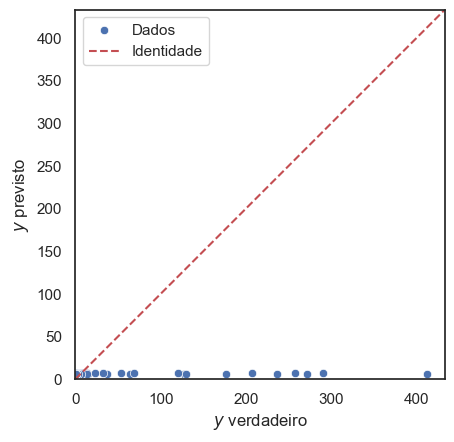

In [68]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

dummy_mean_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", DummyRegressor(strategy="mean"))
    ]
)

def test_kf(model):
    metrics = []
    true_y = []
    pred_y = []

    for train_idx, test_idx in kf.split(X):

        X_train_, X_test_ = X.iloc[train_idx], X.iloc[test_idx]
        y_train_, y_test_ = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train_, y_train_)

        true_y_ = y_test_
        pred_y_ = model.predict(X_test_)
        
        true_y.append(true_y_)
        pred_y.append(pred_y_)

        RMSE = root_mean_squared_error(true_y_, pred_y_)

        metrics.append(RMSE)

    print("As métricas foram:\n", *[f"{i} - {metric}\n" for i, metric in enumerate(metrics)])
    print()
    print("A média das métricas é de:", np.mean(metrics))

    true_y = np.concatenate(true_y).ravel()
    pred_y = np.concatenate(pred_y).ravel()

    min_val = min(true_y.min(), pred_y.min())
    max_val = max(true_y.max(), pred_y.max())

    interval = [min_val * 0.95, max_val * 1.05]

    eixo = sns.scatterplot(x=true_y, y=pred_y, label="Dados")
    eixo.plot(interval, interval, "r--", label="Identidade")

    eixo.set(
        xlabel="$y$ verdadeiro",
        ylabel="$y$ previsto",
        xlim=interval,
        ylim=interval,
        aspect="equal",
    )
    eixo.legend();
    
    return metrics
    
dummy_mean_metrics = test_kf(dummy_mean_model)

Como nosso target tem aquela cauda grande para números maiores, isso pode estar influenciando muito a média. Vamos testar a eficiência de um Dummy com a mediana ao invés da média.

As métricas foram:
 0 - 39.89086775471161
 1 - 0.5320512613982309
 2 - 17.908150147331185
 3 - 62.27938053929705
 4 - 10.326280212249568
 5 - 4.727159168225584
 6 - 38.6111731984811
 7 - 31.304457250044177
 8 - 44.296958187685846
 9 - 52.43288389733749


A média das métricas é de: 30.230936161676187


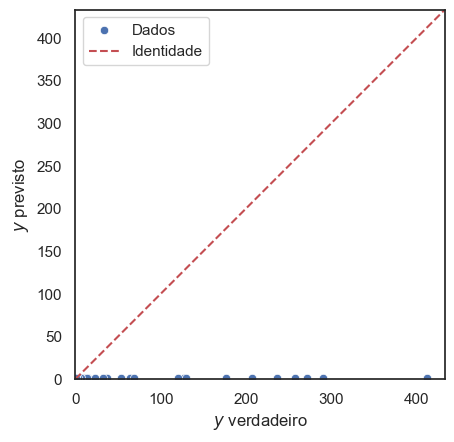

In [69]:
dummy_median_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", DummyRegressor(strategy="median"))
    ]
)

dummy_median_metrics = test_kf(dummy_median_model)

Os resultados parecem essencialmente os mesmos. Vamos ver como os outros modelos lidam com isso.

## <a id='toc1_3_'></a>[Conclusão](#toc0_)

Sendo assim, nosso modelo baseline com a média alcançou um RMSE médio de aproximadamente 30.74x, enquanto o modelo baseado na mediana estimou um RMSE de cerca de 30.23x, levemente melhor.

Esse resultado não é tão bom considerando que a maioria das observações apresenta um fator de amplitude baixo, então o modelo poderia prever muito mais do que devia usualmente.

<span id="referencias"></span>
## <a id='toc1_4_'></a>[Referências](#toc0_)

1. **CASSAR, Daniel R.** *ATP-203 1.1 - Tratamento de dados com pandas*. Campinas: Ilum Escola de Ciência, 2026.
1. **CASSAR, Daniel R.** *ATP-203 3.0 - Modelo linear e baseline*. Campinas: Ilum Escola de Ciência, 2026.